# AI Model Experiment & Evaluation
Sentiment analysis ulasan pelanggan: model klasik (Scikit-learn) vs LLM API (Gemini).

## 1. Problem Statement

- **Objective**: mengklasifikasikan sentimen ulasan produk e-commerce secara otomatis, lalu memilih pendekatan yang layak dikembangkan ke produksi.
- **Target**: kolom `sentiment`, dua kelas, `positif` dan `negatif`. Kelas positif dipakai sebagai `pos_label`.

## 2. Import Library & Load Dataset

In [1]:
import os, re, time, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

logging.getLogger('google_genai').setLevel(logging.ERROR)  # sembunyikan warning AFC dari SDK
SEED = 42
LABELS = ['negatif', 'positif']

df = pd.read_csv('../data/customer_reviews_sentiment.csv')
print(df.shape)
print(df['sentiment'].value_counts())
print('Teks ulasan unik:', df['review_text'].nunique())
df.head()

(200, 4)
sentiment
positif    110
negatif     90
Name: count, dtype: int64
Teks ulasan unik: 40


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


Dataset kecil dan cukup seimbang (110 positif, 90 negatif). Hal yang paling penting: **200 baris hanya berisi 40 kalimat unik**
(20 positif, 20 negatif). Kalimat yang sama muncul berulang dengan `product_name` berbeda, dan setiap kalimat selalu punya label yang sama.

## 3. Menyiapkan Train/Test Split

Split acak per baris seperti di starter notebook membuat kalimat yang sama masuk ke train dan test sekaligus. Hasilnya bisa dicek di bawah:

In [2]:
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(
    df['review_text'], df['sentiment'], test_size=0.2, random_state=SEED, stratify=df['sentiment'])
print(f'Split acak: {X_te_r.isin(set(X_tr_r)).mean():.0%} baris test kalimatnya sudah ada di train')

Split acak: 98% baris test kalimatnya sudah ada di train


Artinya model klasik cukup menghafal kalimat, bukan belajar sentimen. Karena itu split dilakukan **per kalimat unik**:
30% kalimat unik (stratified per label) dijadikan test, lalu semua baris dengan kalimat tersebut ikut ke test.
Test set ini dipakai untuk **kedua** pendekatan.

In [3]:
uniq = df.drop_duplicates('review_text')[['review_text', 'sentiment']]
train_txt, test_txt = train_test_split(uniq['review_text'], test_size=0.3,
                                       random_state=SEED, stratify=uniq['sentiment'])

train_df = df[df['review_text'].isin(train_txt)].reset_index(drop=True)
test_df = df[df['review_text'].isin(test_txt)].reset_index(drop=True)
X_train, y_train = train_df['review_text'], train_df['sentiment']
X_test, y_test = test_df['review_text'], test_df['sentiment']

print('Train:', len(train_df), 'baris /', train_df['review_text'].nunique(), 'kalimat unik')
print('Test :', len(test_df), 'baris /', test_df['review_text'].nunique(), 'kalimat unik')
print('Overlap kalimat train-test:', len(set(X_train) & set(X_test)))
print(y_test.value_counts().to_dict())

Train: 145 baris / 28 kalimat unik
Test : 55 baris / 12 kalimat unik
Overlap kalimat train-test: 0
{'negatif': 30, 'positif': 25}


## 4. Pendekatan 1 - Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction
TF-IDF dengan unigram + bigram. Bigram dipakai supaya frasa seperti `tidak mengecewakan` atau `tidak sesuai` terbaca sebagai satu fitur,
bukan hanya kata `tidak` yang cenderung negatif. Preprocessing lain cukup lowercase (default TF-IDF); stopword tidak dibuang karena kata negasi penting.

In [4]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
print('Jumlah fitur:', X_train_vec.shape[1])

Jumlah fitur: 298


### 4.2 Training Model

In [5]:
clf = LogisticRegression(max_iter=1000, random_state=SEED)
t0 = time.perf_counter()
clf.fit(X_train_vec, y_train)
train_time = time.perf_counter() - t0
print(f'Waktu training: {train_time*1000:.1f} ms')

Waktu training: 3.2 ms


### 4.3 Prediksi pada Test Set

In [6]:
t0 = time.perf_counter()
y_pred_classic = clf.predict(X_test_vec)
classic_ms_per_row = (time.perf_counter() - t0) * 1000 / len(X_test)
print(f'Waktu inferensi: {classic_ms_per_row:.3f} ms per ulasan')

Waktu inferensi: 0.004 ms per ulasan


## 5. Pendekatan 2 - LLM API (Gemini)

### 5.1 Setup API
API key dibaca dari file `.env` (tidak ikut di-commit). Setiap hasil panggilan API langsung disimpan ke `documentation/llm_predictions.csv`.
API hanya dipanggil untuk kalimat yang belum ada di file itu, jadi notebook bisa dijalankan ulang tanpa API key dan tanpa menghabiskan kuota.

In [7]:
MODEL = 'gemini-3.5-flash-lite'
TEMPERATURE = 0.0
MAX_OUTPUT_TOKENS = 10
CACHE_PATH = '../documentation/llm_predictions.csv'

load_dotenv('../.env')
cache = pd.read_csv(CACHE_PATH) if os.path.exists(CACHE_PATH) else pd.DataFrame(columns=['review_text'])
todo = [t for t in uniq['review_text'] if t not in set(cache['review_text'])]
print('Sudah ada di cache:', len(cache), '| perlu dipanggil ke API:', len(todo))

if todo:
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=os.environ['GEMINI_API_KEY'],
                          http_options=types.HttpOptions(timeout=60_000))

Sudah ada di cache: 40 | perlu dipanggil ke API: 0


### 5.2 Merancang Prompt

Teknik **zero-shot**. Few-shot tidak dipakai karena contoh few-shot harus diambil dari data; kalau contohnya mirip kalimat test,
perbandingannya jadi tidak adil. Isi prompt:
- peran dan konteks (ulasan e-commerce Bahasa Indonesia),
- definisi dua label,
- aturan untuk negasi (`tidak mengecewakan` = positif) dan ulasan campuran,
- format jawaban hanya satu kata supaya mudah diparsing.

**Parameter**:
- `temperature=0`: klasifikasi butuh jawaban yang konsisten. Input yang sama harus menghasilkan label yang sama, jadi tidak perlu variasi.
- `max_output_tokens=10`: jawaban yang diharapkan hanya satu kata. Batas ini mencegah model menulis penjelasan panjang, sekaligus menekan biaya.
- Model `gemini-3.5-flash-lite`: task ini sederhana, jadi dipilih varian termurah dan tercepat. Awalnya dicoba `gemini-3.8-flash`, tapi
  model itu memakai ~140 token *thinking* per ulasan (~6 detik per panggilan) dan kuota free tier-nya hanya 20 request/hari.

In [8]:
PROMPT = """Kamu adalah sistem klasifikasi sentimen ulasan produk e-commerce berbahasa Indonesia.

Label:
- positif: pembeli puas atau memuji produk, pengiriman, atau pelayanan.
- negatif: pembeli kecewa atau mengeluhkan produk, pengiriman, atau pelayanan.

Aturan:
- Perhatikan negasi. Contoh: "tidak mengecewakan" berarti positif.
- Jika ulasan campuran, pilih sentimen yang paling dominan.
- Jawab hanya dengan satu kata: positif atau negatif.

Ulasan: "{review}"
Sentimen:"""


def normalize(text):
    t = re.sub(r'[^a-z]', ' ', (text or '').lower()).split()
    found = [w for w in t if w in LABELS]
    return found[0] if len(set(found)) == 1 else 'tidak_valid'


def classify_sentiment_llm(review, retries=5):
    for i in range(retries):
        try:
            t0 = time.perf_counter()
            resp = client.models.generate_content(
                model=MODEL,
                contents=PROMPT.format(review=review),
                config=types.GenerateContentConfig(temperature=TEMPERATURE, max_output_tokens=MAX_OUTPUT_TOKENS),
            )
            u = resp.usage_metadata
            return {'review_text': review, 'model': MODEL, 'raw_output': resp.text,
                    'latency_s': time.perf_counter() - t0,
                    'input_tokens': u.prompt_token_count,
                    'output_tokens': (u.candidates_token_count or 0) + (u.thoughts_token_count or 0)}
        except Exception as e:  # rate limit / server error: tunggu lalu ulang
            print(f'retry {i+1}: {str(e)[:80]}')
            time.sleep(10 * (i + 1))
    raise RuntimeError(f'Gagal memanggil API untuk: {review}')

### 5.3 Menjalankan Prediksi pada Test Set

Karena `temperature=0` dan kalimat yang sama menghasilkan prompt yang sama, API cukup dipanggil **sekali per kalimat unik**, lalu hasilnya dipetakan ke semua baris.
Semua 40 kalimat unik diprediksi. Test set utama hanya memakai 12 kalimat, sisanya dipakai untuk cek stabilitas di Section 6.4.
LLM tidak ditraining, jadi memprediksi kalimat yang masuk train set tidak menimbulkan kebocoran.

In [9]:
for i, review in enumerate(todo, 1):
    row = classify_sentiment_llm(review)
    cache = pd.concat([cache, pd.DataFrame([row])], ignore_index=True)
    cache.to_csv(CACHE_PATH, index=False)  # simpan tiap panggilan
    print(f'{i}/{len(todo)}', repr(row['raw_output']))

llm_df = cache.copy()
llm_df['pred'] = llm_df['raw_output'].apply(normalize)
llm_map = dict(zip(llm_df['review_text'], llm_df['pred']))
y_pred_llm = X_test.map(llm_map)

print('Output tidak valid:', (llm_df['pred'] == 'tidak_valid').sum())
print(f"Latency rata-rata: {llm_df['latency_s'].mean():.2f} s per ulasan")
print(f"Token rata-rata: {llm_df['input_tokens'].mean():.0f} input, {llm_df['output_tokens'].mean():.0f} output (termasuk thinking)")

Output tidak valid: 0
Latency rata-rata: 2.06 s per ulasan
Token rata-rata: 132 input, 2 output (termasuk thinking)


## 6. Evaluasi dan Perbandingan

In [10]:
def evaluate(name, y_true, y_pred):
    print(f'=== {name} ===')
    print(classification_report(y_true, y_pred, labels=LABELS, digits=3, zero_division=0))
    return {'Pendekatan': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, pos_label='positif', zero_division=0),
            'Recall': recall_score(y_true, y_pred, pos_label='positif', zero_division=0),
            'F1-Score': f1_score(y_true, y_pred, pos_label='positif', zero_division=0),
            'F1 Macro': f1_score(y_true, y_pred, average='macro', zero_division=0)}

### 6.1 Evaluasi Model Klasik

In [11]:
res_classic = evaluate('TF-IDF + Logistic Regression', y_test, y_pred_classic)
print(confusion_matrix(y_test, y_pred_classic, labels=LABELS))

=== TF-IDF + Logistic Regression ===
              precision    recall  f1-score   support

     negatif      1.000     0.567     0.723        30
     positif      0.658     1.000     0.794        25

    accuracy                          0.764        55
   macro avg      0.829     0.783     0.759        55
weighted avg      0.844     0.764     0.755        55

[[17 13]
 [ 0 25]]


**Interpretasi model klasik**
- **Accuracy 0.764**: 42 dari 55 ulasan test diprediksi benar.
- **Arah kesalahan**: semua 13 kesalahan berupa ulasan negatif yang diprediksi positif (baris pertama confusion matrix).
  13 baris ini hanya berasal dari 2 kalimat unik yang masing-masing muncul 7 dan 6 kali.
- **Recall positif 1.0**: semua ulasan positif tertangkap. Angka ini tinggi karena model memang condong menebak positif.
- **Precision positif 0.658**: dari 38 ulasan yang diprediksi positif, 13 sebenarnya keluhan.
- **Recall negatif 0.567**: hampir setengah keluhan tidak terdeteksi.
- **F1 positif 0.794, F1 macro 0.759**: meringkas ketimpangan antara precision dan recall di atas.

Untuk fitur halaman produk, kesalahan jenis ini paling merugikan karena keluhan pembeli malah tampil sebagai ulasan positif.

### 6.2 Evaluasi LLM API

In [12]:
res_llm = evaluate(f'Gemini ({MODEL}, zero-shot)', y_test, y_pred_llm)
print(confusion_matrix(y_test, y_pred_llm, labels=LABELS))

=== Gemini (gemini-3.5-flash-lite, zero-shot) ===
              precision    recall  f1-score   support

     negatif      1.000     1.000     1.000        30
     positif      1.000     1.000     1.000        25

    accuracy                          1.000        55
   macro avg      1.000     1.000     1.000        55
weighted avg      1.000     1.000     1.000        55

[[30  0]
 [ 0 25]]


**Interpretasi LLM**
- **Accuracy, precision, recall, dan F1 semuanya 1.0**: Gemini benar di seluruh 55 ulasan test, dan confusion matrix-nya hanya terisi di diagonal.
- **Output selalu valid**: semua jawaban model sudah berupa satu kata label, jadi tidak ada jawaban yang dibuang saat normalisasi.

Angka sempurna ini perlu dibaca hati-hati. Test set hanya berisi 12 kalimat unik yang pendek dan sentimennya jelas.
Kondisi itu belum mewakili ulasan asli, yang sering ambigu, sarkastik, campuran, atau memakai bahasa gaul.

### 6.3 Tabel Perbandingan Ringkasan

In [13]:
summary = pd.DataFrame([res_classic, res_llm]).set_index('Pendekatan')
summary['Training'] = [f'{train_time*1000:.0f} ms', 'tidak ada']
summary['Inferensi / ulasan'] = [f'{classic_ms_per_row:.3f} ms', f"{llm_df['latency_s'].mean():.2f} s"]
summary.round(3)

,Accuracy,Precision,Recall,F1-Score,F1 Macro,Training,Inferensi / ulasan
Pendekatan,,,,,,,
TF-IDF + Logistic Regression,0.764,0.658,1.0,0.794,0.759,3 ms,0.004 ms
"Gemini (gemini-3.5-flash-lite, zero-shot)",1.000,1.000,1.0,1.000,1.000,tidak ada,2.06 s


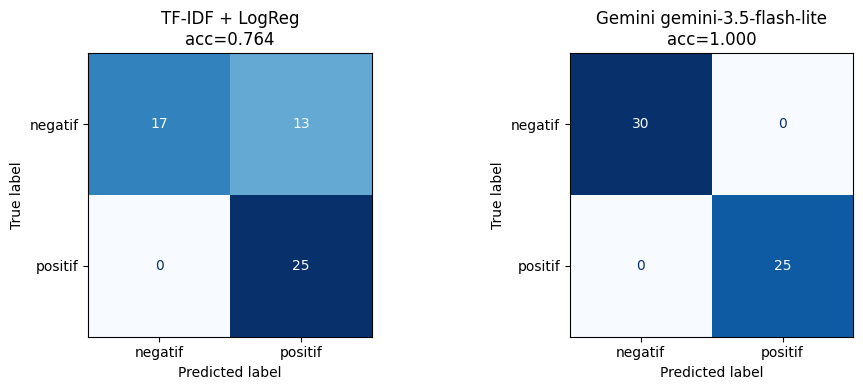

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [('TF-IDF + LogReg', y_pred_classic), (f'Gemini {MODEL}', y_pred_llm)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=LABELS, cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{name}\nacc={accuracy_score(y_test, pred):.3f}')
plt.tight_layout()
plt.savefig('../documentation/model_comparison_summary.png', dpi=150)
plt.show()

### 6.4 Cek Stabilitas dan Error Analysis

Test set utama hanya berisi 12 kalimat unik, jadi satu kalimat yang salah bisa menggeser metrik cukup jauh.
Sebagai pembanding: model klasik dievaluasi dengan 5-fold cross-validation per kalimat (`StratifiedGroupKFold`), sedangkan LLM dievaluasi di seluruh 200 baris.
Hasil model klasik pada split acak (yang bocor) juga ditampilkan untuk menunjukkan efek kebocoran.

In [15]:
pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000, random_state=SEED))
cv = cross_validate(pipe, df['review_text'], df['sentiment'], groups=df['review_text'],
                    cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED),
                    scoring=['accuracy', 'f1_macro'])
leaky = pipe.fit(X_tr_r, y_tr_r).predict(X_te_r)
llm_all = df['review_text'].map(llm_map)

pd.DataFrame({
    'Accuracy': [accuracy_score(y_te_r, leaky), cv['test_accuracy'].mean(), accuracy_score(df['sentiment'], llm_all)],
    'F1 Macro': [f1_score(y_te_r, leaky, average='macro'), cv['test_f1_macro'].mean(), f1_score(df['sentiment'], llm_all, average='macro')],
}, index=['Klasik - split acak (bocor)', 'Klasik - 5-fold per kalimat (mean)', 'Gemini - seluruh 200 baris']).round(3)

,Accuracy,F1 Macro
Klasik - split acak (bocor),1.000,1.000
Klasik - 5-fold per kalimat (mean),0.445,0.441
Gemini - seluruh 200 baris,1.000,1.000


In [16]:
print('Std accuracy 5-fold klasik:', cv['test_accuracy'].std().round(3))
err = test_df[['review_text', 'sentiment']].assign(klasik=y_pred_classic, gemini=y_pred_llm.values).drop_duplicates('review_text')
err['proba_positif_klasik'] = clf.predict_proba(vectorizer.transform(err['review_text']))[:, 1].round(2)
print('Kalimat unik yang salah diprediksi di test set:')
err[(err['sentiment'] != err['klasik']) | (err['sentiment'] != err['gemini'])]

Std accuracy 5-fold klasik: 0.088
Kalimat unik yang salah diprediksi di test set:


,review_text,sentiment,klasik,gemini,proba_positif_klasik
8,Respon penjual lambat dan terkesan tidak pedul...,negatif,positif,negatif,0.52
10,"Ukuran dan warna berbeda dari pesanan, sangat ...",negatif,positif,negatif,0.54


In [17]:
# kalimat yang salah diprediksi Gemini di seluruh dataset
wrong_llm = llm_df.merge(uniq, on='review_text').query('pred != sentiment')[['review_text', 'sentiment', 'raw_output']]
wrong_llm if len(wrong_llm) else 'Tidak ada kesalahan Gemini pada 40 kalimat unik.'

'Tidak ada kesalahan Gemini pada 40 kalimat unik.'

**Temuan**
- **Split acak menyesatkan.** Dengan split acak, model klasik mendapat skor 1.0 karena 98% kalimat test sudah dilihat saat training. Skor itu hasil menghafal kalimat.
- **Skor 0.764 di test utama termasuk beruntung.** Dengan 5-fold per kalimat, accuracy rata-rata model klasik hanya 0.445 (std 0.088).
  Angka ini di bawah baseline tebak kelas mayoritas (0.55). Data train hanya berisi sekitar 28-32 kalimat unik, dan kosakatanya terlalu sedikit untuk dipelajari.
- **Penyebab dua kalimat yang salah diprediksi.** Model belajar bobot dari kata yang tidak membawa sentimen:
  - `Respon penjual lambat dan terkesan tidak peduli komplain.` Kata `respon` (+0.55) dan `dan` (+0.45) dianggap positif karena di train muncul di "Fast respon" dan "Respon cepat". Bobot itu mengalahkan `lambat` dan `tidak`.
  - `Ukuran dan warna berbeda dari pesanan, sangat kecewa.` Kata `ukuran` (+0.39) dan `sangat` (+0.42) dianggap positif. Kata kunci `kecewa` tidak pernah muncul di train (yang ada hanya `mengecewakan`), jadi tidak punya bobot.
  - Probabilitas positif kedua kalimat hanya 0.52-0.54. Model sebenarnya ragu, dan bias intercept ke kelas positif (85 vs 60 baris train) yang mendorongnya ke positif.
- **Gemini** benar di ke-40 kalimat unik (seluruh 200 baris), termasuk kalimat dengan negasi seperti "tidak mengecewakan" dan "tidak ada cacat".

## 7. Analisis Trade-off dan Limitation

**Performa.** Gemini unggul jelas: F1 1.0 vs 0.794 di test set yang sama, dan 1.0 vs rata-rata 0.44 pada cross-validation.
Model klasik gagal karena datanya hanya 40 kalimat unik. Masalahnya ada di jumlah data, bukan di algoritma TF-IDF + Logistic Regression.

| Aspek | Model klasik (TF-IDF + LogReg) | LLM API (Gemini flash-lite) |
|---|---|---|
| Effort implementasi | Perlu data berlabel, training, dan evaluasi ulang tiap data berubah | Tanpa training, cukup menulis prompt dan parsing output |
| Kebutuhan data | Butuh ratusan sampai ribuan ulasan unik berlabel | Tidak butuh data training, data berlabel hanya untuk evaluasi |
| Kecepatan inferensi | ~0.004 ms per ulasan, lokal | ~1-2 detik per ulasan (network + antrean API) |
| Biaya | Hampir nol; training 3 ms di CPU | Bayar per token: ~132 token input + 2 token output per ulasan. 1 juta ulasan ≈ 132 juta token input |
| Ketergantungan | Tidak ada, berjalan offline | Butuh internet, API key, kuota, dan bergantung pada ketersediaan model dari Google |
| Konsistensi | Deterministik | `temperature=0` hampir deterministik, tapi output bisa berubah kalau versi model diganti |

**Limitation model klasik**
- Tidak mengenal kata yang tidak ada di data train (contoh: `kecewa`).
- Mudah belajar korelasi palsu dari kata netral (`respon`, `dan`, `sangat`).
- Bag-of-words tidak memahami negasi atau urutan kata, kecuali frasanya kebetulan ada sebagai bigram di data train.
- Terpengaruh duplikat: kalimat yang muncul 12 kali mendapat bobot 12 kali lipat.

**Limitation LLM**
- **Kuota dan limit.** Selama eksperimen muncul error 429. `gemini-3.8-flash` hanya dapat 20 request/hari di free tier, dan `gemini-3.5-flash-lite` sempat kena limit per menit.
- **Latensi.** Sekitar 2 detik per ulasan, sedangkan model klasik di bawah 1 ms.
- **Model bisa berubah.** `gemini-2.5-flash` di starter notebook sudah tidak tersedia untuk user baru, jadi hasil eksperimen bisa bergeser kalau model diganti.
- **Output teks bebas.** Tetap perlu normalisasi dan penanganan output tidak valid.
- **Privasi.** Teks ulasan dikirim ke pihak ketiga.
- **Validasi terbatas.** Hasil 1.0 hanya divalidasi di 40 kalimat yang mudah.

**Limitation eksperimen**
- Test set kecil (12 kalimat unik), jadi satu kalimat bisa menggeser accuracy sekitar 12%.
- Dataset sintetis dan bersih, belum mewakili ulasan asli.

## 8. Rekomendasi Technical Approach

**Rekomendasi: kembangkan pendekatan LLM API (Gemini flash-lite, zero-shot) untuk tahap awal produksi.
Sambil berjalan, kumpulkan data berlabel untuk melatih model klasik nanti.**

Alasan:
1. **Hanya LLM yang terbukti bisa generalisasi ke kalimat baru.** Dengan data yang ada, model klasik rata-rata di bawah baseline (accuracy 0.445 di CV per kalimat).
   Skor 1.0 dari split acak hanya hasil menghafal. Menambah data sampai model klasik layak butuh waktu dan biaya anotasi.
2. **Kesalahan model klasik paling berbahaya untuk use case ini.** Keluhan terbaca sebagai ulasan positif (recall negatif 0.567).
   Gemini tidak membuat kesalahan ini di seluruh data.
3. **Biaya dan latensi LLM masih bisa diterima.** Klasifikasi sentimen ulasan tidak perlu real-time.
   Prediksi bisa dijalankan secara batch saat ulasan masuk, lalu disimpan, jadi latensi 1-2 detik tidak terasa oleh pembeli.
   Tiap ulasan cukup diklasifikasikan sekali. Dengan ~134 token per ulasan dan model kelas flash-lite, biaya per ulasan kecil.
   Free tier tidak cukup untuk produksi, jadi perlu paid tier.

Syarat sebelum go-live:
- Validasi ulang dengan beberapa ratus ulasan asli yang dilabeli manual, termasuk yang ambigu dan sarkastik.
- Kunci versi model, simpan prediksi, dan pasang retry/backoff untuk error 429.
- Simpan hasil prediksi LLM sebagai label awal. Setelah terkumpul ribuan ulasan unik, latih ulang model klasik dan bandingkan lagi.
  Kalau performanya mendekati LLM, pindah ke model klasik untuk menghemat biaya dan menghilangkan ketergantungan pada API.